In [ ]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Embedding
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import re
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Copy of Tweets.csv")
df = df[['text', 'sentiment']].copy()
df = df.dropna()

In [ ]:
# Text Cleaning
def clean_tweets(tweet):
  tweet = tweet.lower()
  # Remove Links
  tweet = re.sub(r'https?:\S+|www\.\S+', '', tweet)
  # Replace ` with '
  tweet = tweet.replace('`', "'")
  # Remove Mentions
  tweet = re.sub(r'@\w+', '', tweet)
  # Handle abbreviations like 'll, 's, etc.
  tweet = re.sub(r'n\'t', ' not', tweet)
  tweet = re.sub(r'\'s', ' is', tweet)
  tweet = re.sub(r'\'re', ' are', tweet)
  tweet = re.sub(r'\'d', ' would', tweet)
  tweet = re.sub(r'\'ll', ' will', tweet)
  tweet = re.sub(r'\'ve', ' have', tweet)
  tweet = re.sub(r'\'m', ' am', tweet)
  # Handle emojies like <3, etc.
  tweet = re.sub(r'<3', 'love', tweet)
  tweet = re.sub(r':\)', 'smile', tweet)
  tweet = re.sub(r':\(', 'sad', tweet)
  # Remove punctuation
  tweet = re.sub(r'[^\w\s]', '', tweet)
  # Remove numbers
  tweet = re.sub(r'\d+', '', tweet)
  # Remove extra whitespaces
  tweet = re.sub(r'\s+', ' ', tweet)
  return tweet

df['text'] = df['text'].apply(clean_tweets)

# Tokenization
df['tokens'] = df['text'].apply(nltk.word_tokenize)

# remove stop-wrods
stop_words = set(nltk.corpus.stopwords.words('english'))
df['tokens'] = df['tokens'].apply(lambda x: [word for word in x if word not in stop_words])

# Stemming
stemmer = nltk.stem.PorterStemmer()
df['stemmed_tokens'] = df['tokens'].apply(lambda x: [stemmer.stem(word) for word in x])
df['stemmed_tokens'].head(10)


,stemmed_tokens
0,"[would, respond, go]"
1,"[sooo, sad, miss, san, diego]"
2,"[boss, bulli]"
3,"[interview, leav, alon]"
4,"[son, could, put, releas, alreadi, bought]"
5,"[shameless, plug, best, ranger, forum, earth]"
6,"[feed, babi, fun, smile, coo]"
7,"[soooo, high]"
8,[]
9,"[journey, wow, u, becam, cooler, hehe, possibl]"


In [ ]:
# split data into train/test/validation
data = df[['stemmed_tokens','sentiment']]
from sklearn.model_selection import train_test_split
train, test = train_test_split(data, test_size=0.2, random_state=42)
train, val = train_test_split(train, test_size=0.2, random_state=42)

print("Train size:", len(train))
print("Test size:", len(test))
print("Validation size:", len(val))

Train size: 17587
Test size: 5496
Validation size: 4397


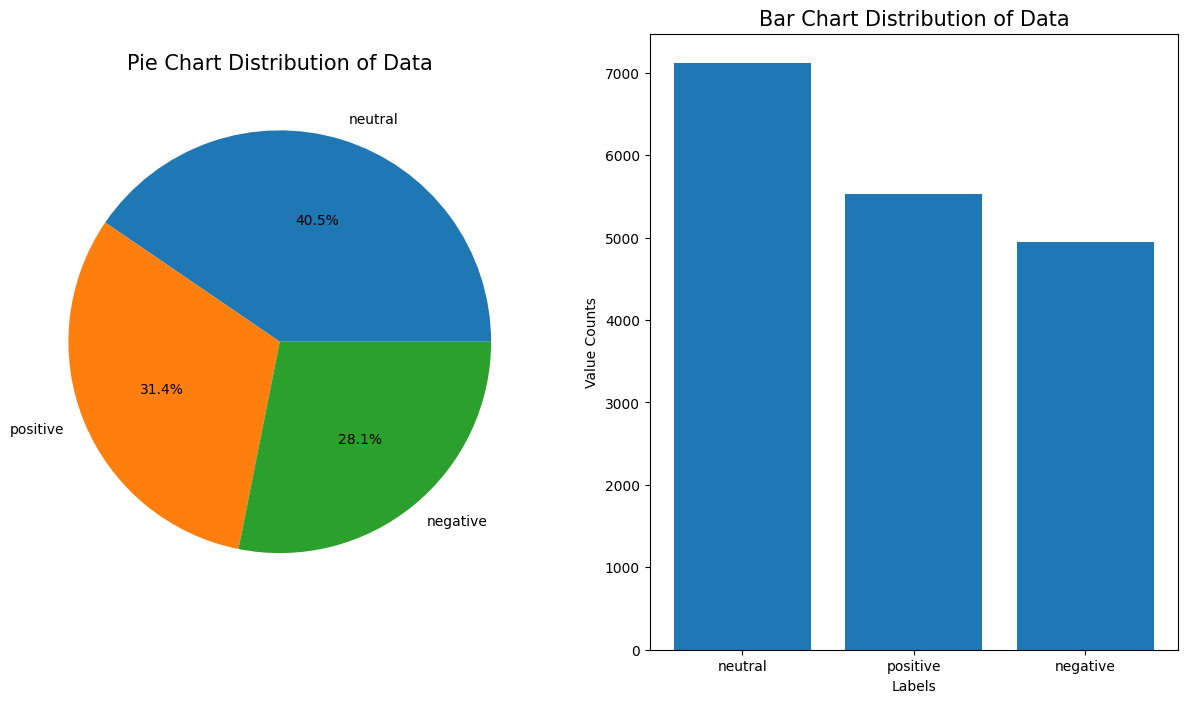

In [ ]:
# Viusalize class distributions

classes_dict = Counter(train['sentiment'])
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
ax[0].pie(classes_dict.values(), labels=classes_dict.keys(), autopct='%.1f%%')
ax[0].set_title("Pie Chart Distribution of Data", fontsize=15)
ax[1].bar(classes_dict.keys(), classes_dict.values())
ax[1].set_title("Bar Chart Distribution of Data", fontsize=15)
ax[1].set_xlabel("Labels")
ax[1].set_ylabel("Value Counts")
plt.show()

In [ ]:
# Encode labels
encoder = LabelEncoder()
train['sentiment'] = encoder.fit_transform(train['sentiment'])
test['sentiment'] = encoder.transform(test['sentiment'])
val['sentiment'] = encoder.transform(val['sentiment'])

In [ ]:
for x in train['stemmed_tokens']:
  print(x)
  break

['_brown', 'there', 'holi', 'version', 'hell', 'loli', 'cant', 'stop', 'need', 'trend', 'topic', 'nice', 'whisper', 'redmangolol']


In [ ]:
train['stemmed_tokens']

,stemmed_tokens
10232,"[_brown, there, holi, version, hell, loli, can..."
11845,"[welcom, xuxu]"
21037,"[shite, night, tomorow, get, hang, littl, brot..."
13390,"[need, simpl, reminderthx]"
4013,"[watch, one, fav, movi, sparkl, go, get, food,..."
...,...
2686,"[plant, flover, school, garden, yr, oldveri, m..."
301,"[made, sad, thought, would, jump, joy]"
10899,"[live, nobodi]"
12134,"[sound, good, ca, wait]"


In [ ]:
import numpy as np

# Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts(train['stemmed_tokens'])

train_seqs = tokenizer.texts_to_sequences(train['stemmed_tokens'])
val_seqs = tokenizer.texts_to_sequences(val['stemmed_tokens'])
test_seqs = tokenizer.texts_to_sequences(test['stemmed_tokens'])

# Pad sequences
maxlen = max([len(x) for x in train['stemmed_tokens'].to_list()])  # Determine max length
x_train = pad_sequences(train_seqs, maxlen=maxlen)
x_val = pad_sequences(val_seqs, maxlen=maxlen)
x_test = pad_sequences(test_seqs, maxlen=maxlen)

y_train = np.array(train['sentiment'])
y_val = np.array(val['sentiment'])
y_test = np.array(test['sentiment'])

In [ ]:
# Train RNN model on the data
model = Sequential([
    Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=32),
    LSTM(32),
    Dense(len(classes_dict), activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=16
)


Epoch 1/5
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.6213 - loss: 0.8289 - val_accuracy: 0.6866 - val_loss: 0.7377
Epoch 2/5
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.7743 - loss: 0.5644 - val_accuracy: 0.7012 - val_loss: 0.7540
Epoch 3/5
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8489 - loss: 0.4078 - val_accuracy: 0.6761 - val_loss: 0.8544
Epoch 4/5
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8894 - loss: 0.3120 - val_accuracy: 0.6684 - val_loss: 0.9713
Epoch 5/5
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9119 - loss: 0.2508 - val_accuracy: 0.6702 - val_loss: 1.0702


In [ ]:
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy: {:.2f}%".format(accuracy * 100))

172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6534 - loss: 1.0644
Test Loss: 1.064411997795105
Test Accuracy: 65.34%


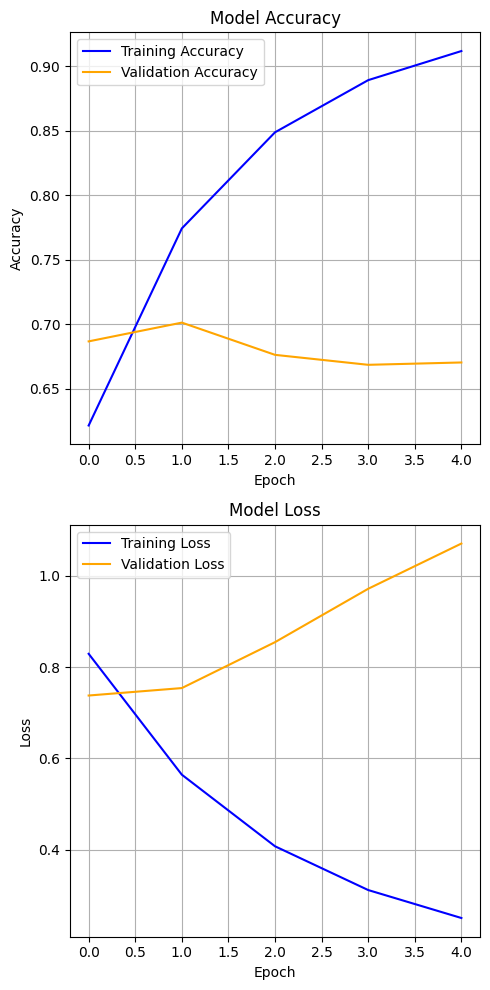

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(5, 10))

# Accuracy Plot
ax[0].plot(history.history['accuracy'], label='Training Accuracy', color='blue')
ax[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
ax[0].set_title('Model Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[0].grid(True)

# Loss Plot
ax[1].plot(history.history['loss'], label='Training Loss', color='blue')
ax[1].plot(history.history['val_loss'], label='Validation Loss', color='orange')
ax[1].set_title('Model Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


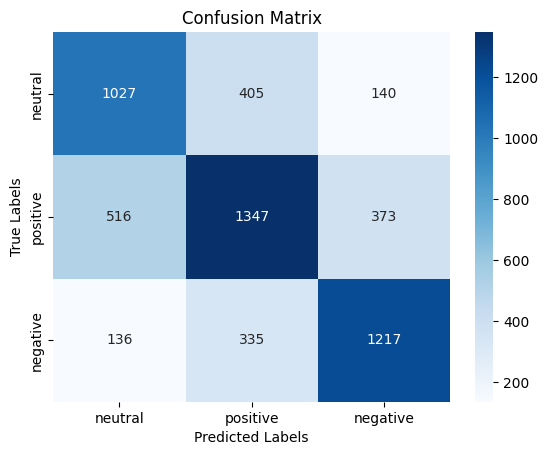

In [ ]:
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, predicted_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes_dict.keys(), yticklabels=classes_dict.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()